# Targeting drive replacement at Halyard Storage


## Setup

### Setting the working directory


In [1]:
import os

# COURSE_DIR is the folder that holds the HW/ and Lectures/ subfolders. It is
# found automatically by walking up from wherever this notebook is stored. If
# you have moved the notebook, set it by hand instead, for example:
#     COURSE_DIR = '/path/to/15.071 AI Edge 2026'
COURSE_DIR = os.path.abspath(os.getcwd())
while not all(os.path.isdir(os.path.join(COURSE_DIR, d)) for d in ('HW', 'Lectures')):
    parent = os.path.dirname(COURSE_DIR)
    if parent == COURSE_DIR:
        raise RuntimeError('Course folder not found: set COURSE_DIR by hand above.')
    COURSE_DIR = parent

os.chdir(os.path.join(COURSE_DIR, 'HW', 'HW4'))
print('Working directory:', os.getcwd())

Working directory: /Users/hongyuyue/Documents/26fall Course Code/The AI Edge/HW/HW4


### Loading packages

The usual libraries, plus the tree-based models from `scikit-learn`.


In [2]:
#these libraries help us manipulate data
import numpy as np
import pandas as pd

#these help us run models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

#these are for graphics
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


## 1. The fleet, and the policy Halyard runs today

Each row is one hard drive, described as it stood on the first day of a quarter, together with what happened to it
over the ninety days that followed. `failed_within_90_days` is 1 if the drive failed in service during that quarter
and 0 if it survived it. The file covers two consecutive quarters, marked `Q1` and `Q2`.


In [3]:
fleet = pd.read_csv('fleet.csv.gz')
LABEL = 'failed_within_90_days'

display(fleet)


,drive_id,quarter,vendor,drive_model,capacity_tb,site,age_years,power_cycles,start_stop_count,load_cycles,...,reallocated_sectors,pending_sectors,offline_uncorrectable,uncorrectable_errors,command_timeouts,crc_errors,head_flying_hours,tb_written,tb_read,failed_within_90_days
0,Q1-000000,Q1,Vendor A,A-12TB-02,12.0,Site 2,3.78,6,6.0,1627.0,...,0.0,0.0,0.0,0.0,0.0,0.0,32917.0,56.0,253.0,0
1,Q1-000001,Q1,Vendor A,A-8TB-04,8.0,Site 2,6.54,20,20.0,183.0,...,0.0,0.0,0.0,0.0,0.0,0.0,57341.0,51.7,237.1,0
2,Q1-000002,Q1,Vendor B,B-16TB-01,16.0,Site 1,2.05,3,4.0,101.0,...,0.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
3,Q1-000003,Q1,Vendor C,C-16TB-02,16.0,Site 4,0.78,8,8.0,943.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
4,Q1-000004,Q1,Vendor D,D-4TB-04,4.0,Site 1,6.80,10,12.0,1131.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537931,Q2-274009,Q2,Vendor B,B-16TB-02,16.0,Site 1,2.51,12,12.0,854.0,...,0.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
537932,Q2-274010,Q2,Vendor D,D-12TB-02,12.0,Site 3,2.94,5,5.0,954.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
537933,Q2-274011,Q2,Vendor A,A-8TB-04,8.0,Site 2,6.72,14,14.0,71919.0,...,0.0,0.0,0.0,0.0,0.0,0.0,58886.0,53.6,284.1,0
537934,Q2-274012,Q2,Vendor A,A-16TB-02,16.0,Site 2,2.52,6,5.0,28585.0,...,0.0,0.0,0.0,0.0,0.0,0.0,14044.0,7.1,31.1,0


The columns fall into three groups.

**What the drive is**: `vendor`, `drive_model`, `capacity_tb`, and the `site` it lives in.

**How hard it has worked**: `age_years` (powered-on time), `power_cycles`, `start_stop_count`, `load_cycles`,
`emergency_retracts`, `head_flying_hours`, `tb_written`, `tb_read`, and `temperature_c`.

**What has already gone wrong inside it**: telemetry data keeping track of the errors that the drive's own firmware has detected and
worked around. `reallocated_sectors` counts sectors found bad and mapped out to spares. `pending_sectors` counts
sectors that failed a read and are waiting to be reallocated. `offline_uncorrectable`, `uncorrectable_errors` and
`command_timeouts` count errors the drive could not recover from at all. `crc_errors`, `seek_error_rate`,
`read_error_rate`, `spin_up_time` and `spin_retry_count` describe the mechanics.

Note also that some counters are blank for part of the fleet. That is not an issue of the drive itself, but a difference between manufacturers in what
their firmware chooses to report.

We display some statistics on the failure rate in each quarter.

In [8]:
display(fleet.groupby('quarter')[LABEL] #先按quarter分组，再只取LABEL这一列 groupby doesn't tell me anything until i tell it how to summerize each group
        .agg(drives='size', failures='sum', failure_rate='mean') #.agg分组后作汇总硬盘数、故障数和故障率
        .assign(failure_rate=lambda d: (100 * d.failure_rate).round(3))) #.assign 新增或覆盖一列故障率

,drives,failures,failure_rate
quarter,,,
Q1,263922,900,0.341
Q2,274014,1112,0.406


### Splitting the data

We divide the two quarters rather than shuffling all the drives together: **every model is built on Q1 and judged on
Q2.** This split mirrors the question Halyard is asking: having seen last quarter, how well can
we call the next one?

A random split would mix the two quarters on both sides. Because the fleet changes slowly, that would let a model
learn from drives sitting in the same racks, running the same firmware, in the same weeks as the drives it is then
tested on （同一时期、同一机架、同一固件的硬盘彼此很像，随机打乱测试集里每块硬盘几乎都能在训练集里找到很像的"兄弟"，模型相当于提前看到了答案的一部分，分数会虚高。）. This is partly reflected by the different failure rates between the two quarters. It might therefore artificially improve the model's performance through data leakage.


In [ ]:
fleet_train = fleet[fleet.quarter == 'Q1'].reset_index(drop=True)
fleet_test  = fleet[fleet.quarter == 'Q2'].reset_index(drop=True)

,drive_id,quarter,vendor,drive_model,capacity_tb,site,age_years,power_cycles,start_stop_count,load_cycles,...,reallocated_sectors,pending_sectors,offline_uncorrectable,uncorrectable_errors,command_timeouts,crc_errors,head_flying_hours,tb_written,tb_read,failed_within_90_days
0,Q2-000000,Q2,Vendor A,A-16TB-02,16.0,Site 1,0.87,8,8.0,2246.0,...,0.0,0.0,0.0,0.0,0.0,0.0,7263.0,51.4,58.4,0
1,Q2-000001,Q2,Vendor C,C-16TB-02,16.0,Site 1,1.59,15,15.0,2829.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
2,Q2-000002,Q2,Vendor B,B-16TB-01,16.0,Site 4,1.10,19,19.0,38.0,...,4.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
3,Q2-000003,Q2,Vendor B,B-16TB-01,16.0,Site 4,0.57,11,11.0,21.0,...,0.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
4,Q2-000004,Q2,Vendor D,D-4TB-03,4.0,Site 2,9.32,11,11.0,1255.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274009,Q2-274009,Q2,Vendor B,B-16TB-02,16.0,Site 1,2.51,12,12.0,854.0,...,0.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
274010,Q2-274010,Q2,Vendor D,D-12TB-02,12.0,Site 3,2.94,5,5.0,954.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
274011,Q2-274011,Q2,Vendor A,A-8TB-04,8.0,Site 2,6.72,14,14.0,71919.0,...,0.0,0.0,0.0,0.0,0.0,0.0,58886.0,53.6,284.1,0
274012,Q2-274012,Q2,Vendor A,A-16TB-02,16.0,Site 2,2.52,6,5.0,28585.0,...,0.0,0.0,0.0,0.0,0.0,0.0,14044.0,7.1,31.1,0


### Is age a good guide to which drives are about to fail?

Halyard's current policy retires drives at five years, regardless of condition. The plot below shows the failure rate as a function of how old the drive was when the quarter began.


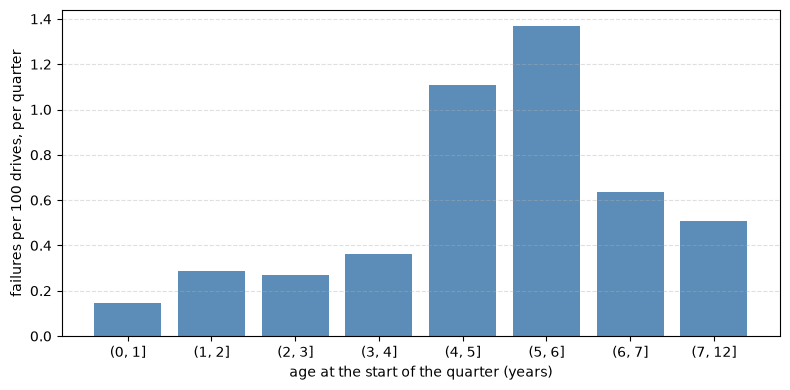

In [ ]:
bands = pd.cut(fleet_test.age_years, [0, 1, 2, 3, 4, 5, 6, 7, 12])
by_age = (fleet_test.groupby(bands)[LABEL]
          .agg(drives='size', failures='sum', failure_rate='mean'))

#matplotlib画图
plt.figure(figsize=(8, 4))
plt.bar([str(i) for i in by_age.index], 100 * by_age.failure_rate, color='#5b8db8')
plt.ylabel('failures per 100 drives, per quarter')
plt.xlabel('age at the start of the quarter (years)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout(); plt.show()


**Takeaway**: age carries some signal, but far less than the policy assumes. The failure rate rises to a peak between four and six years and then actually *falls* for the oldest drives in the
fleet. Old drives are survivors: whatever weeds out the fragile ones has largely
finished doing so. The five-year rule retires drives at almost exactly the moment they stop being the riskiest ones.


### What the five-year rule actually catches

A drive is retired in the quarter in which it passes five years of powered-on service.


In [ ]:
RETIRE_AGE = 5.0
QUARTER    = 90 / 365.25

due_this_quarter = ((fleet_test.age_years <  RETIRE_AGE) &
                    (fleet_test.age_years >= RETIRE_AGE - QUARTER))

failed_this_quarter = fleet_test[LABEL].sum() #实际坏掉的
caught_this_quarter = fleet_test.loc[due_this_quarter, LABEL].sum() #本季度我们认为有风险取走的有多少真坏了

print(f"failures in the fleet as a whole          : {failed_this_quarter}")
BUDGET_NOW = int(due_this_quarter.sum())#本季度我们认为有风险取走的
print(f"drives reaching {RETIRE_AGE} years this quarter : {BUDGET_NOW:,} "
      f"({BUDGET_NOW / len(fleet_test):.2%} of the fleet)")
print(f"of which failed in service                : {caught_this_quarter} "
      f"({caught_this_quarter / failed_this_quarter:.1%} of the failures)")

#更换成本：5,573 × $80
#避免的故障损失：78 × $5,200
#整体来说还是亏了


failures in the fleet as a whole          : 1112
drives reaching 5.0 years this quarter : 5,573 (2.03% of the fleet)
of which failed in service                : 78 (7.0% of the failures)


In [15]:
display(fleet_train)

,drive_id,quarter,vendor,drive_model,capacity_tb,site,age_years,power_cycles,start_stop_count,load_cycles,...,reallocated_sectors,pending_sectors,offline_uncorrectable,uncorrectable_errors,command_timeouts,crc_errors,head_flying_hours,tb_written,tb_read,failed_within_90_days
0,Q1-000000,Q1,Vendor A,A-12TB-02,12.0,Site 2,3.78,6,6.0,1627.0,...,0.0,0.0,0.0,0.0,0.0,0.0,32917.0,56.0,253.0,0
1,Q1-000001,Q1,Vendor A,A-8TB-04,8.0,Site 2,6.54,20,20.0,183.0,...,0.0,0.0,0.0,0.0,0.0,0.0,57341.0,51.7,237.1,0
2,Q1-000002,Q1,Vendor B,B-16TB-01,16.0,Site 1,2.05,3,4.0,101.0,...,0.0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0
3,Q1-000003,Q1,Vendor C,C-16TB-02,16.0,Site 4,0.78,8,8.0,943.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
4,Q1-000004,Q1,Vendor D,D-4TB-04,4.0,Site 1,6.80,10,12.0,1131.0,...,0.0,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
263917,Q1-263917,Q1,Vendor A,A-8TB-01,8.0,Site 2,7.17,9,9.0,76342.0,...,0.0,0.0,0.0,0.0,0.0,0.0,62815.0,57.8,256.0,0
263918,Q1-263918,Q1,Vendor A,A-16TB-02,16.0,Site 2,2.64,5,5.0,3979.0,...,0.0,0.0,0.0,0.0,0.0,0.0,22329.0,48.0,149.6,0
263919,Q1-263919,Q1,Vendor A,A-12TB-04,12.0,Site 1,3.63,3,4.0,1717.0,...,0.0,0.0,0.0,0.0,0.0,0.0,31528.0,59.8,271.9,0
263920,Q1-263920,Q1,Vendor A,A-12TB-02,12.0,Site 3,3.42,12,12.0,1445.0,...,0.0,0.0,0.0,0.0,0.0,0.0,29800.0,48.8,163.9,0


**Takeaway**: the fleet suffers 1,112 in-service failures in the quarter. The 5,573 replacements Halyard performs
catch 78 of them. The program consumes the whole of the field team's maintenance capacity but fails to identify the majority of the failing drives.

## 2. Data pre-processing

We convert `vendor`, `site` and `drive_model` into indicator columns. There are enough distinct drive models that we keep the twenty most common and group the rest as `other`.

Some counters are missing for part of the fleet. We fill those blanks with the median of the training quarter so that
every model has a complete table to work with, and for each counter that is blank for more than 5% of the training quarter we add a
`_reported` column recording whether the value was there to start with.


In [22]:
CATEGORICAL = ['vendor', 'drive_model', 'site']
NUMERIC     = [c for c in fleet_train.columns
               if c not in CATEGORICAL + ['drive_id', 'quarter', LABEL]] #LABEL = 'failed_within_90_days'

SPARSE      = [c for c in NUMERIC if fleet_train[c].isna().mean() > 0.05] #求空缺比例大的变量列

common_models = fleet_train.drive_model.value_counts().head(20).index #value_count 统计每个号出现了多少次，默认从多到少排序
for df in (fleet_train, fleet_test):
    df['drive_model'] = df.drive_model.where(df.drive_model.isin(common_models), 'other')

def build_features(df, medians=None):
    X = df[NUMERIC].copy()
    for c in SPARSE: #对缺的值比较多的column
        X[c + '_reported'] = df[c].notna().astype(int) #notna()得到True/False，astype转为0/1
    if medians is None: #没有medians时
        medians = X.median() #计算each column的median
    X = X.fillna(medians) #fillna会按列名，对应着blank填medians。
    return pd.concat([X, pd.get_dummies(df[CATEGORICAL])], axis=1), medians #返回将numericX和one-hot处理后的Categorial 与medians 一起返回

X_train, medians = build_features(fleet_train)
X_test, _        = build_features(fleet_test, medians)
X_test           = X_test.reindex(columns=X_train.columns, fill_value=0) #担心test没有train里的个别type或多出个别type，做one-hot导致column对不上，将缺少的column添加为0，多出的column删掉

y_train = fleet_train[LABEL].values
y_test  = fleet_test[LABEL].values

## 3. From a risk score to a replacement plan

A model gives every drive a probability of failure. We devise a maintenance program and estimate its impact using three parameters:

— Planned replacement cost: \$80

— In-service failure cost: \$5,200

— Capacity: 5,573 swaps this quarter. For every model, we pick the 5,573 drives with the highest probability of failure and measure how many of the quarter's real failures were in that list.

This is defined in the following helper function.


In [ ]:
COST_PLANNED = 80      # a replacement made in a scheduled maintenance window
COST_FAILURE = 5200     # a drive that fails in service

def replacement_plan(risk, label, budget=BUDGET_NOW, quiet=False): #risk Q2每块硬盘的风险分数，budget能换多少块
    risk    = np.asarray(risk, dtype=float) #转化为浮点数
    pulled  = np.argsort(-risk)[:budget] #把-risk按从小到大排列 取前budget个
    caught  = int(y_test[pulled].sum()) #换出来的里面有多少个真的有问题
    missed  = int(y_test.sum()) - caught #有多少个真的有问题的没抓到
    cost    = budget * COST_PLANNED + missed * COST_FAILURE

    summary = {'failures caught': caught,
               'share of all failures': caught / y_test.sum(),
               'hit rate of the pull list': caught / budget,
               'quarterly cost': cost}
    if not quiet:
        print(f"{label}")
        print(f"  drives pulled            : {budget:,}")
        print(f"  failures caught          : {caught:,} of {y_test.sum():,} "
              f"({caught / y_test.sum():.1%})")
        print(f"  hit rate of the pull list: {caught / budget:.1%}")
        print(f"  quarterly cost           : ${cost:,.0f}")
    return summary


We check that the function replicates the earlier results under the current policy, and estimate its cost.

In [24]:
results_calendar = replacement_plan(due_this_quarter.values.astype(float),
                                    'Calendar: retire at 5 years')


Calendar: retire at 5 years
  drives pulled            : 5,573
  failures caught          : 78 of 1,112 (7.0%)
  hit rate of the pull list: 1.4%
  quarterly cost           : $5,822,640


## 4. Two models

### Logistic regression


In [ ]:
scaler = StandardScaler().fit(X_train) #算出每个特征的均值和标准差，存进 scaler

#logisticregression默认有regularization，具体alpha（在这里为C）为固定值1
logistic = LogisticRegression(max_iter=3000).fit(scaler.transform(X_train), y_train)#scaler.transform为standardization（mean=0,standard deviation=1）迭代3000次，default=100，特征多了不好收敛
risk_logistic = logistic.predict_proba(scaler.transform(X_test))[:, 1]#predict_proba 对每块硬盘输出两列概率：[P(不坏), P(坏)]

print(f"area under the ROC curve: {roc_auc_score(y_test, risk_logistic):.3f}\n") #打印AUC
results_logistic = replacement_plan(risk_logistic, 'Logistic regression')


area under the ROC curve: 0.746

Logistic regression
  drives pulled            : 5,573
  failures caught          : 247 of 1,112 (22.2%)
  hit rate of the pull list: 4.4%
  quarterly cost           : $4,943,840


**Takeaway**: The model improves upon the current policy, with 247 failures caught instead of 78. This shows the benefits of the information contained in the telemetry data. Still, the model catches only 22% of the failures, which leaves some room for improvement.

### Classification tree

A tree asks a sequence of yes/no questions and assigns each drive to a leaf-based prediction. We hold the tree to a depth of four, and require at least 100 drives in any group it creates, so that what comes out
is small enough to read and each group is large enough to trust.


In [ ]:
#一颗决策树，最多四层，每个叶子最少100个sample，固定随机种子
#此处的随机种子指的是：sklearn 会随机打乱特征的考察顺序。 如果两个切分方式效果完全一样（打平），选哪个取决于谁先被考察到，而这个顺序是随机的。
#tree面对one-hot，每一列0/1都当作一个变量去尝试切
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100,
                              random_state=1).fit(X_train, y_train)
risk_tree = tree.predict_proba(X_test)[:, 1] #只取出坏的那列的概率

print(f"area under the ROC curve: {roc_auc_score(y_test, risk_tree):.3f}")
print(f"groups in the tree      : {tree.get_n_leaves()}\n")
results_tree = replacement_plan(risk_tree, 'Classification tree')


area under the ROC curve: 0.742
groups in the tree      : 13

Classification tree
  drives pulled            : 5,573
  failures caught          : 539 of 1,112 (48.5%)
  hit rate of the pull list: 9.7%
  quarterly cost           : $3,425,440


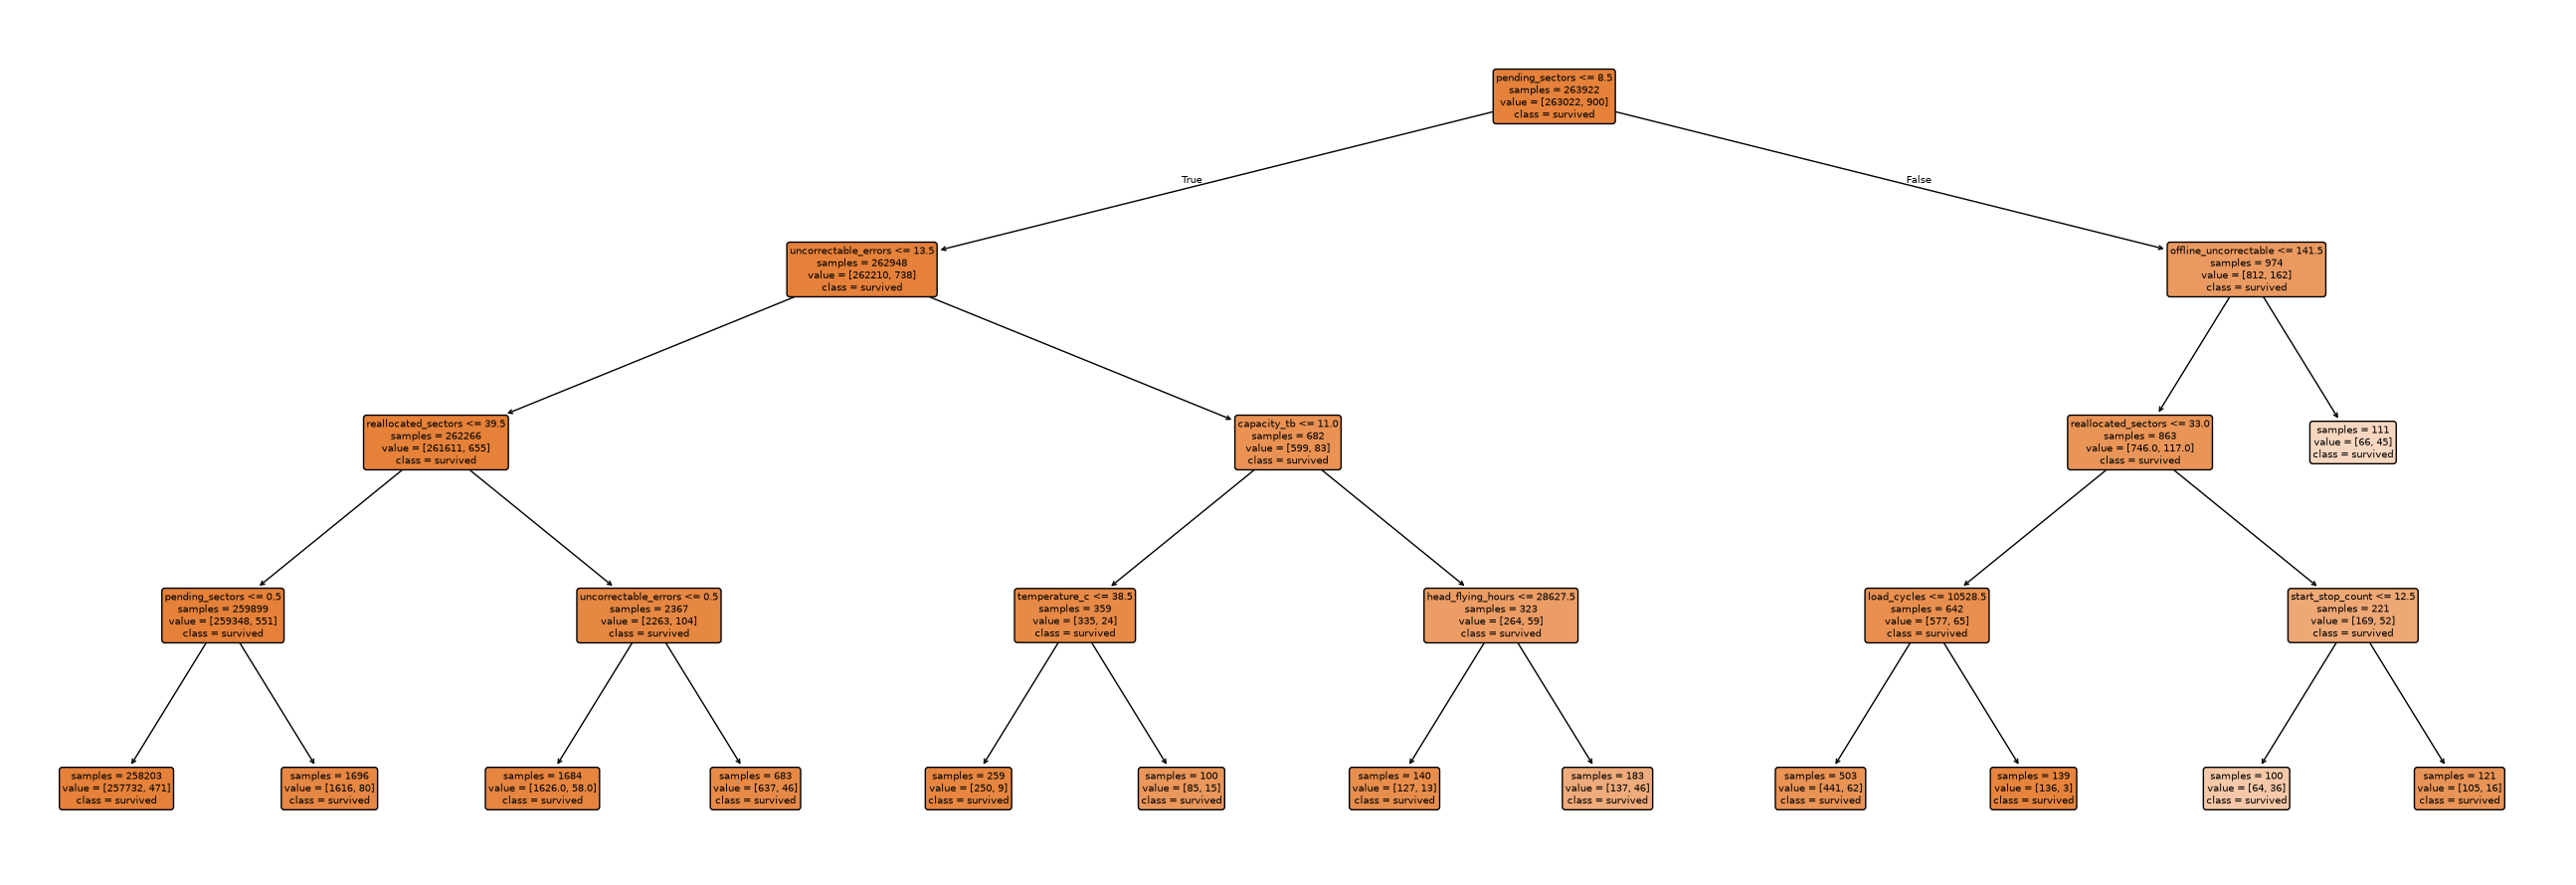

In [29]:
plt.figure(figsize=(26, 9))
plot_tree(tree, feature_names=list(X_train.columns), class_names=['survived', 'failed'],
          filled=True, rounded=True, impurity=False, fontsize=7)
plt.tight_layout(); plt.show()


**Takeaway**: the tree catches **539** of the quarter's failures, more than twice as many as the logistic regression model. The tree first splits on whether `pending_sectors` is above eight. This is the type of thresholds that a linear classifier cannot capture by itself.

## 5. Can a collection of trees do better?

A single tree is easy to read but crude: it carves the fleet into thirteen groups and gives every drive in a group
the same answer. Ensemble methods build many trees instead and combine them, which buys finer distinctions at the cost of a more complex model.

> ### ▸ YOUR TASK 1 --- fit a random forest
>
> Fit a `RandomForestClassifier` on `X_train` and `y_train`, store the predicted failure probabilities for the
> scoring quarter in `risk_forest`, and put it through `replacement_plan` under the name `'Random forest'`,
> storing what it returns as `results_forest`.
>
> Use `n_estimators=300`, `min_samples_leaf=20`, `max_features='sqrt'`, `n_jobs=-1` and `random_state=1`.
>
> *Hint.* The structure is the same as for the classification tree model. Expect this cell to take a few minutes to run.


In [40]:
# ---- YOUR CODE HERE ---------------------------------------

forest         = RandomForestClassifier(n_estimators=300,min_samples_leaf=20,max_features='sqrt',n_jobs=-1,random_state=1).fit(X_train,y_train)
risk_forest    = forest.predict_proba(X_test)[:,1]
results_forest = replacement_plan(risk_forest,'RandomForest')


RandomForest
  drives pulled            : 5,573
  failures caught          : 522 of 1,112 (46.9%)
  hit rate of the pull list: 9.4%
  quarterly cost           : $3,513,840


##我自己写的方法可视化

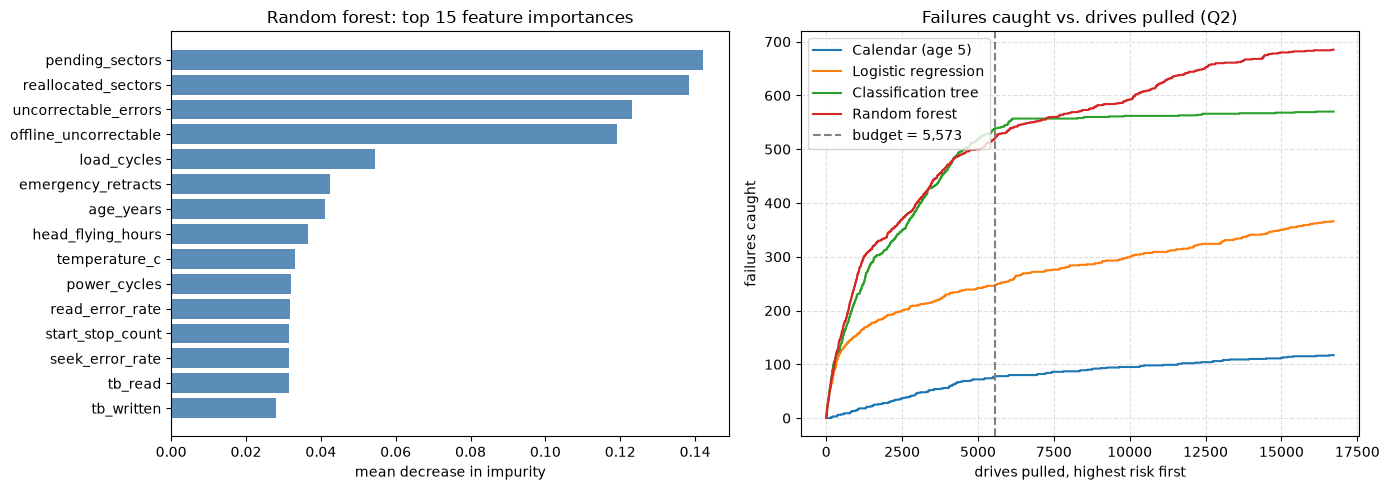

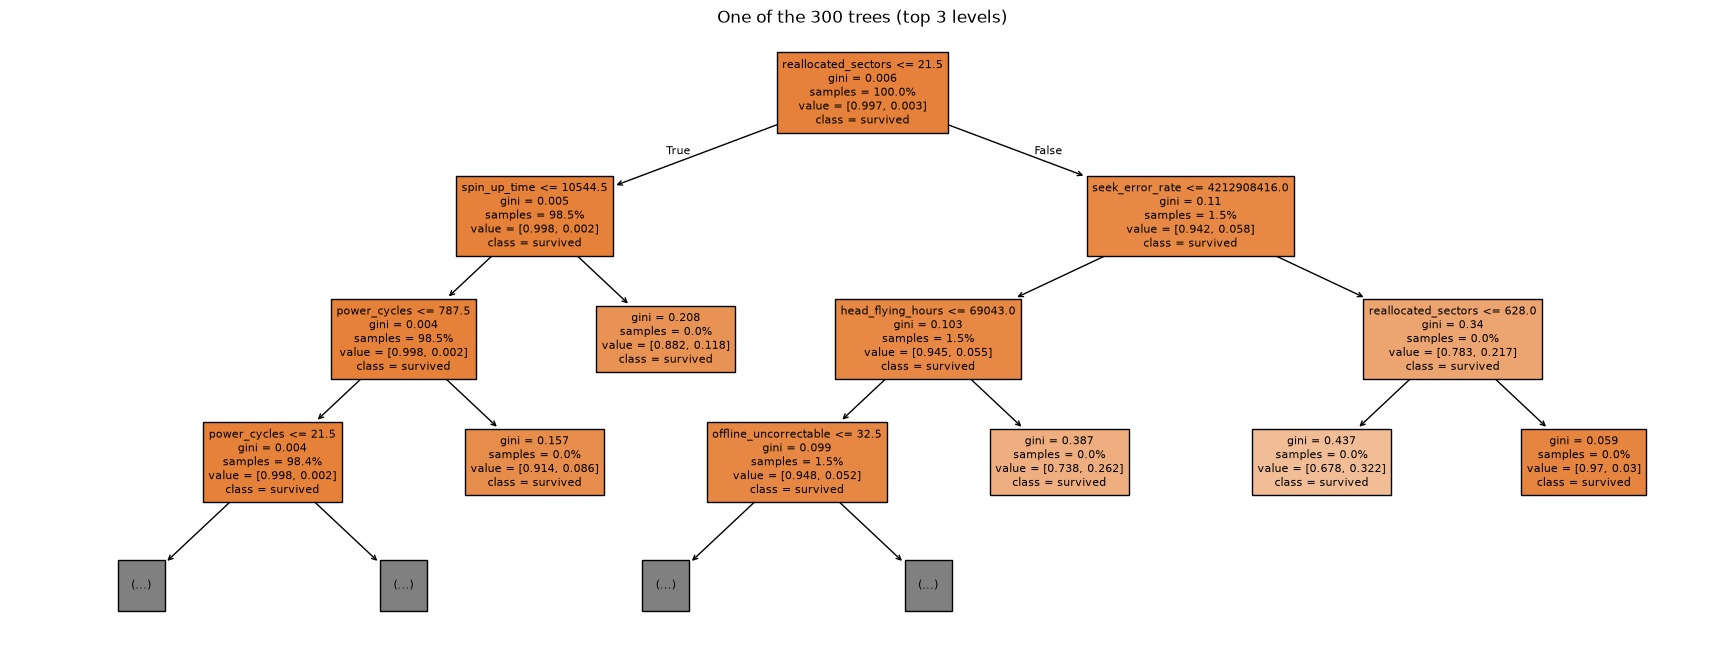

In [ ]:

# 1) 特征重要性 + 2) 累计拦截曲线
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp = (pd.Series(forest.feature_importances_, index=X_train.columns)
         .sort_values().tail(15))
axes[0].barh(imp.index, imp.values, color='#5b8db8')
axes[0].set_title('Random forest: top 15 feature importances')
axes[0].set_xlabel('mean decrease in impurity')

curves = {'Calendar (age 5)':    due_this_quarter.values.astype(float),
          'Logistic regression': risk_logistic,
          'Classification tree': risk_tree,
          'Random forest':       risk_forest}
x_max = 3 * BUDGET_NOW
for name, r in curves.items():
    caught = np.cumsum(y_test[np.argsort(-np.asarray(r))])[:x_max]
    axes[1].plot(np.arange(1, x_max + 1), caught, label=name)
axes[1].axvline(BUDGET_NOW, color='grey', linestyle='--', label=f'budget = {BUDGET_NOW:,}')
axes[1].set_title('Failures caught vs. drives pulled (Q2)')
axes[1].set_xlabel('drives pulled, highest risk first')
axes[1].set_ylabel('failures caught')
axes[1].legend()
axes[1].grid(linestyle='--', alpha=0.4)
plt.tight_layout(); plt.show()

# 3) 森林中的一棵树（只画前 3 层，否则太大看不清）
plt.figure(figsize=(22, 8))
plot_tree(forest.estimators_[0], max_depth=3, feature_names=list(X_train.columns),
          class_names=['survived', 'failed'], filled=True, proportion=True, fontsize=8)
plt.title('One of the 300 trees (top 3 levels)')
plt.show()


> ### ▸ YOUR TASK 2 --- fit a gradient boosting model
>
> Do the same with a `HistGradientBoostingClassifier`, storing the probabilities in `risk_boosted` and reporting it
> under the name `'Gradient boosting'`, storing what it returns as `results_boosted`.
>
> Use `max_iter=400`, `learning_rate=0.05`, `max_depth=4`, `max_features=0.7`, `min_samples_leaf=20`,
> `l2_regularization=50`, `early_stopping=False` and `random_state=1`.
>
> *Hint.* This is scikit-learn's fast implementation of gradient boosting. `max_iter` is the number of trees it builds,
> one after another; `early_stopping=False` makes sure it builds all 400 of them.


In [50]:
# ---- YOUR CODE HERE ---------------------------------------

#400棵，学习率0.05，每次切分只看70%特征，
#此处的regularization定义的是lossfunction里面惩罚每一步修改值的，惩罚叶子数量的在sklearn默认为0
boosted         = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,max_depth=4,max_features=0.7,
                                                 min_samples_leaf=20,l2_regularization=50,early_stopping=False,random_state=1).fit(X_train,y_train)
risk_boosted    = boosted.predict_proba(X_test)[:,1]
results_boosted = replacement_plan(risk_boosted,'GradientBoosting')


GradientBoosting
  drives pulled            : 5,573
  failures caught          : 549 of 1,112 (49.4%)
  hit rate of the pull list: 9.9%
  quarterly cost           : $3,373,440


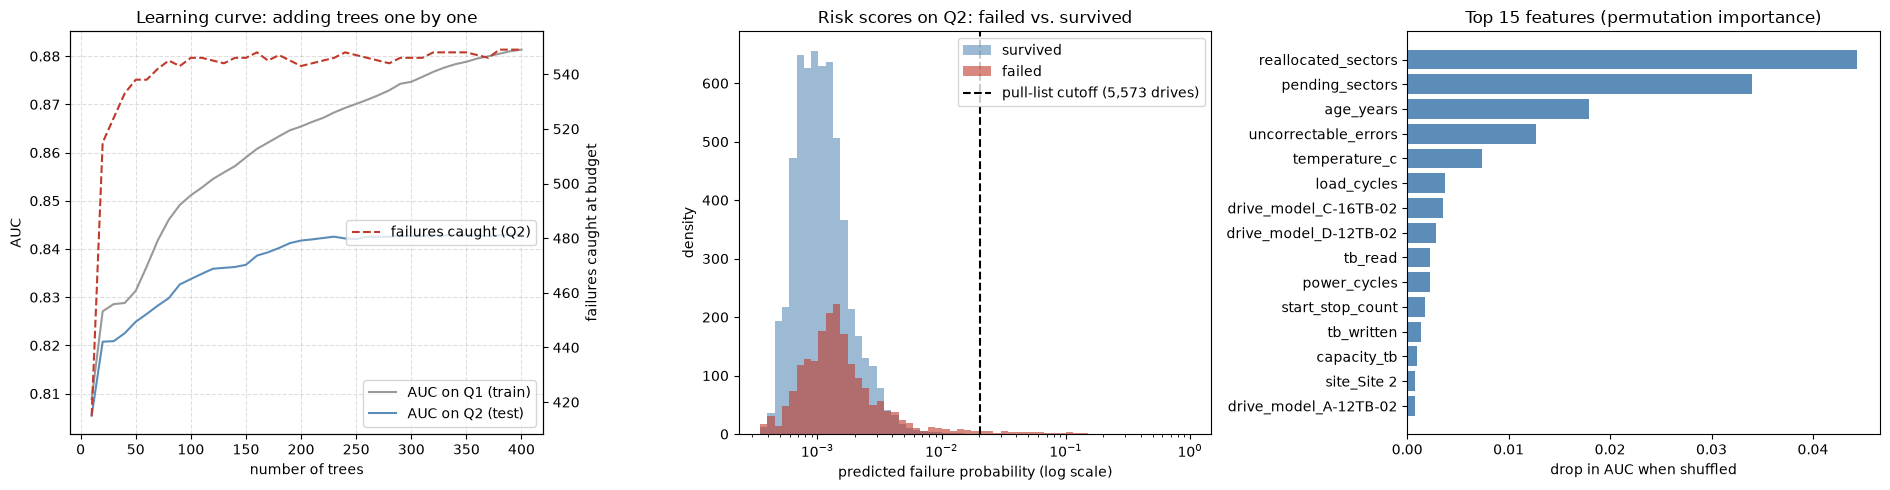

In [51]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1) 学习曲线：树一棵棵加上去，效果怎么变化
STEP = 10
n_trees, auc_tr, auc_te, caught_te = [], [], [], []
for i, (p_tr, p_te) in enumerate(zip(boosted.staged_predict_proba(X_train),
                                     boosted.staged_predict_proba(X_test)), start=1):
    if i % STEP and i != boosted.n_iter_:
        continue
    n_trees.append(i)
    auc_tr.append(roc_auc_score(y_train, p_tr[:, 1]))
    auc_te.append(roc_auc_score(y_test,  p_te[:, 1]))
    caught_te.append(replacement_plan(p_te[:, 1], '', quiet=True)['failures caught'])

ax = axes[0]
ax.plot(n_trees, auc_tr, label='AUC on Q1 (train)', color='#999999')
ax.plot(n_trees, auc_te, label='AUC on Q2 (test)',  color='#5b8db8')
ax.set_xlabel('number of trees'); ax.set_ylabel('AUC')
ax2 = ax.twinx()
ax2.plot(n_trees, caught_te, color='#c0392b', linestyle='--', label='failures caught (Q2)')
ax2.set_ylabel('failures caught at budget')
ax.legend(loc='lower right'); ax2.legend(loc='center right')
ax.set_title('Learning curve: adding trees one by one')
ax.grid(linestyle='--', alpha=0.4)

# 2) 风险分数分布：坏的和没坏的分得开吗
ax = axes[1]
bins = np.logspace(np.log10(risk_boosted.min()), 0, 60)
ax.hist(risk_boosted[y_test == 0], bins=bins, alpha=0.6, density=True, label='survived', color='#5b8db8')
ax.hist(risk_boosted[y_test == 1], bins=bins, alpha=0.6, density=True, label='failed',   color='#c0392b')
cutoff = np.sort(risk_boosted)[-BUDGET_NOW]
ax.axvline(cutoff, color='black', linestyle='--', label=f'pull-list cutoff ({BUDGET_NOW:,} drives)')
ax.set_xscale('log'); ax.set_xlabel('predicted failure probability (log scale)'); ax.set_ylabel('density')
ax.set_title('Risk scores on Q2: failed vs. survived')
ax.legend()

# 3) 置换重要性：打乱某个特征后 AUC 掉多少（抽样 50,000 行以加快速度）
rng = np.random.default_rng(1)
idx = rng.choice(len(X_test), size=min(50_000, len(X_test)), replace=False)
perm = permutation_importance(boosted, X_test.iloc[idx], y_test[idx], scoring='roc_auc',
                              n_repeats=3, random_state=1, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(15)
ax = axes[2]
ax.barh(imp.index, imp.values, color='#5b8db8')
ax.set_xlabel('drop in AUC when shuffled')
ax.set_title('Top 15 features (permutation importance)')

plt.tight_layout(); plt.show()


## 6. Comparing the policies

We inspect the impact of each policy under the same number of swaps (5,573).


In [43]:
comparison = pd.DataFrame({'Calendar: retire at 5 years': results_calendar,
                           'Logistic regression':         results_logistic,
                           'Classification tree':          results_tree,
                           'Random forest':                results_forest,
                           'Gradient boosting':            results_boosted}).T

comparison['saved vs calendar, per quarter'] = (
    results_calendar['quarterly cost'] - comparison['quarterly cost'])
comparison['saved vs calendar, per year'] = 4 * comparison['saved vs calendar, per quarter']

def readable(df, pct=(), money=()):
    out = df.copy()
    for c in out.columns:
        if   c in pct:   out[c] = out[c].map('{:.1%}'.format)
        elif c in money: out[c] = out[c].map('${:,.0f}'.format)
        else:            out[c] = out[c].map('{:,.0f}'.format)
    return out

display(readable(comparison,
                 pct=('share of all failures', 'hit rate of the pull list'),
                 money=('quarterly cost', 'saved vs calendar, per quarter',
                        'saved vs calendar, per year')))


,failures caught,share of all failures,hit rate of the pull list,quarterly cost,"saved vs calendar, per quarter","saved vs calendar, per year"
Calendar: retire at 5 years,78,7.0%,1.4%,"$5,822,640",$0,$0
Logistic regression,247,22.2%,4.4%,"$4,943,840","$878,800","$3,515,200"
Classification tree,539,48.5%,9.7%,"$3,425,440","$2,397,200","$9,588,800"
Random forest,522,46.9%,9.4%,"$3,513,840","$2,308,800","$9,235,200"
Gradient boosting,549,49.4%,9.9%,"$3,373,440","$2,449,200","$9,796,800"


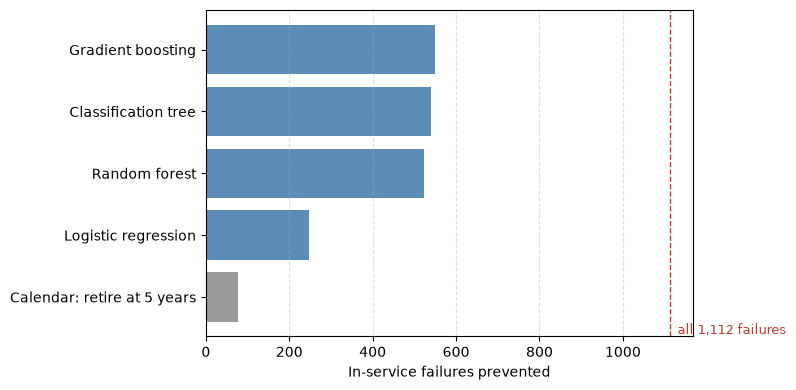

In [44]:
plot_df = comparison.sort_values('failures caught')

plt.figure(figsize=(8, 4))
plt.barh(plot_df.index, plot_df['failures caught'],
         color=['#999999' if 'Calendar' in m else '#5b8db8' for m in plot_df.index])
plt.axvline(y_test.sum(), color='#c0392b', linestyle='--', linewidth=1)
plt.text(y_test.sum(), -0.6, f'  all {y_test.sum():,} failures', color='#c0392b', fontsize=9)
plt.xlabel('In-service failures prevented')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout(); plt.show()


## 7. Should Halyard fund the extra maintenance crew?

Everything above holds capacity fixed at what the company already spends. Facilities has costed an extra crew that
would raise it to about 8,500 swaps a quarter---an extra 2,927 replacements. The crew is worth funding if those extra swaps prevent a sufficient number of failures to break even.


> ### ▸ YOUR TASK 3 --- price the extra crew
>
> For each policy, work out what it would achieve with a budget of `BUDGET_EXPANDED` rather than `BUDGET_NOW`. Compute the additional failures caught, the cost savings, and the net savings against the price of the extra crew.
>
> *Hint.* `replacement_plan` takes a `budget` argument, so you can re-run any model at the larger budget by passing it
> the risk scores you already computed: `risk_logistic`, `risk_tree`, `risk_forest`, `risk_boosted`. Pass
> `quiet=True` to suppress the printout.
>
> Leave the calendar rule out: expanding it would mean lowering the retirement age, which is a different policy altogether rather than a bigger version of this one. Focus on the four machine learning models.


In [ ]:
BUDGET_EXPANDED = 8500
EXTRA_SWAPS     = BUDGET_EXPANDED - BUDGET_NOW
EXTRA_COST      = EXTRA_SWAPS * COST_PLANNED


# ---- YOUR CODE HERE ---------------------------------------
def my_method(risk,label,budget=BUDGET_NOW, quiet=False):
    risk    = np.asarray(risk, dtype=float) #转化为浮点数
    pulled_new  = np.argsort(-risk)[:budget] #把-risk按从小到大排列 取前budget个
    pulled_old  = np.argsort(-risk)[:BUDGET_NOW]
    caught_new  = int(y_test[pulled_new].sum()) #换出来的里面有多少个真的有问题
    caught_old  = int(y_test[pulled_old].sum()) #换出来的里面有多少个真的有问题
    missed_new  = int(y_test.sum()) - caught_new #有多少个真的有问题的没抓到
    missed_old  = int(y_test.sum()) - caught_old
    benefit    = (BUDGET_NOW * COST_PLANNED + missed_old * COST_FAILURE)-(budget * COST_PLANNED + missed_new * COST_FAILURE)
    print(label)
    print(f"rate new:{(caught_new - caught_old)/(budget-BUDGET_NOW):.3%}")
    print(f"total caught: {caught_new}, extra caught: {caught_new - caught_old}")
    print(f"benefit by expand budget: {benefit}")

a= my_method(risk_logistic, 'logistic',budget=BUDGET_EXPANDED)
a= my_method(risk_tree, 'tree',budget=BUDGET_EXPANDED)
a= my_method(risk_forest, 'forest',budget=BUDGET_EXPANDED)
a= my_method(risk_boosted, 'boosted',budget=BUDGET_EXPANDED)


logistic
rate new:1.298%
total caught: 285, extra caught: 38
benefit by expand budget: -36560
tree
rate new:3.120%
total caught: 557, extra caught: 18
benefit by expand budget: 47440
forest
rate new:1.742%
total caught: 573, extra caught: 51
benefit by expand budget: 31040
boosted
rate new:2.426%
total caught: 620, extra caught: 71
benefit by expand budget: 135040


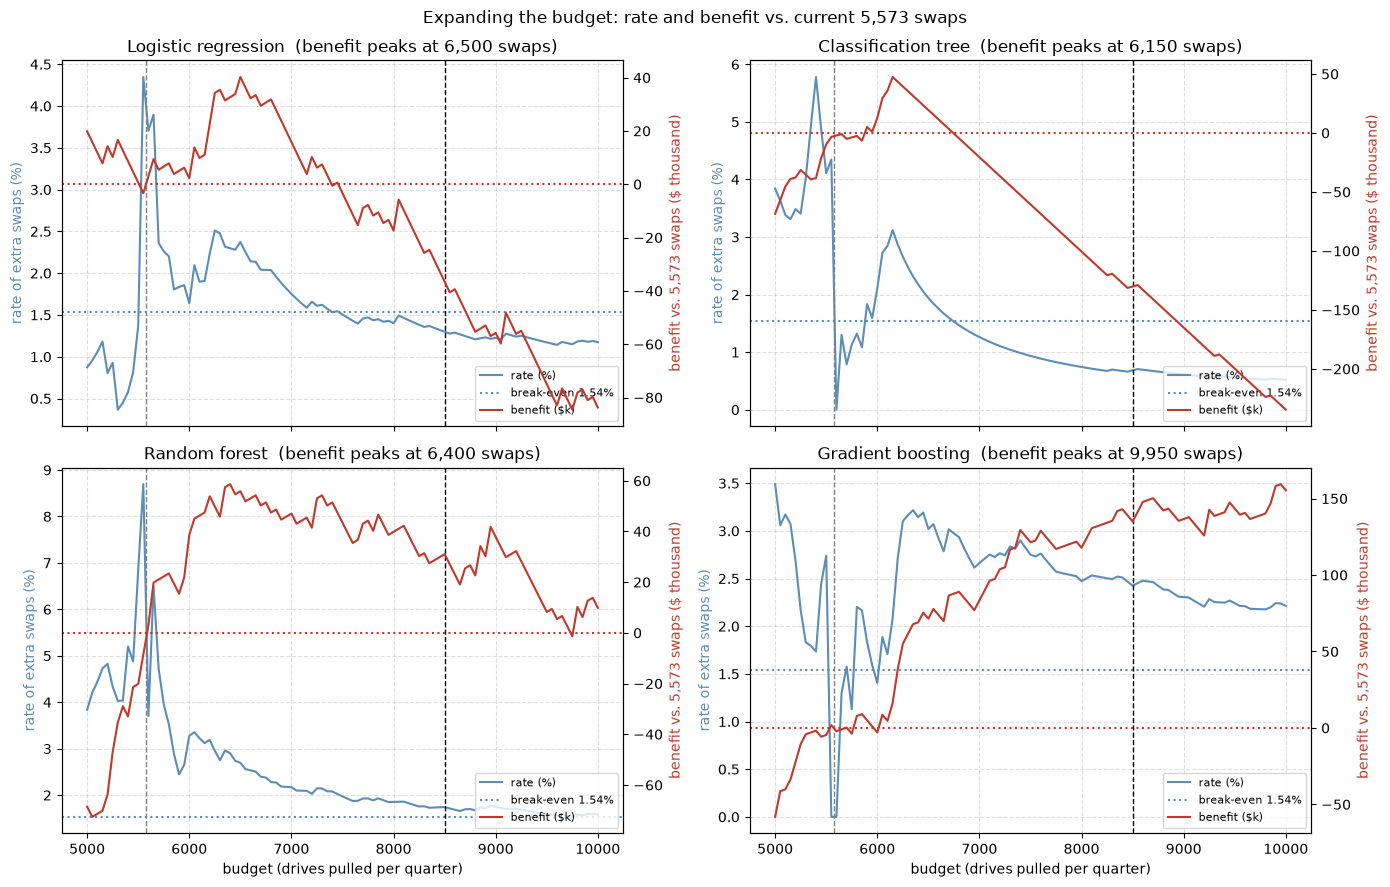

In [76]:
budgets = np.array([b for b in range(5000, 10001, 50) if b != BUDGET_NOW])   # 跳过 5573（分母为 0）
models  = {'Logistic regression': risk_logistic,
           'Classification tree': risk_tree,
           'Random forest':       risk_forest,
           'Gradient boosting':   risk_boosted}
BREAK_EVEN = COST_PLANNED / COST_FAILURE

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, (name, risk) in zip(axes.flat, models.items()):
    order  = np.argsort(-np.asarray(risk, dtype=float))
    cum    = np.concatenate([[0], np.cumsum(y_test[order])])      # cum[b] = 前 b 块里拦下的故障数
    extra  = cum[budgets] - cum[BUDGET_NOW]                        # 和 5573 相比多拦下的
    rate   = extra / (budgets - BUDGET_NOW)                        # 你的 rate
    benefit = (BUDGET_NOW - budgets) * COST_PLANNED + extra * COST_FAILURE   # 你的 benefit（旧成本 - 新成本）

    ax.plot(budgets, 100 * rate, color='#5b8db8', label='rate (%)')
    ax.axhline(100 * BREAK_EVEN, color='#5b8db8', linestyle=':', label=f'break-even {BREAK_EVEN:.2%}')
    ax.set_ylabel('rate of extra swaps (%)', color='#5b8db8')

    ax2 = ax.twinx()
    ax2.plot(budgets, benefit / 1000, color='#c0392b', label='benefit ($k)')
    ax2.axhline(0, color='#c0392b', linestyle=':')
    ax2.set_ylabel('benefit vs. 5,573 swaps ($ thousand)', color='#c0392b')

    ax.axvline(BUDGET_NOW,      color='grey', linestyle='--', linewidth=1)
    ax.axvline(BUDGET_EXPANDED, color='black', linestyle='--', linewidth=1)
    best = budgets[np.argmax(benefit)]
    ax.set_title(f'{name}  (benefit peaks at {best:,} swaps)')
    ax.grid(linestyle='--', alpha=0.4)
    lines = ax.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc='lower right', fontsize=8)

for ax in axes[1]:
    ax.set_xlabel('budget (drives pulled per quarter)')
plt.suptitle('Expanding the budget: rate and benefit vs. current 5,573 swaps')
plt.tight_layout(); plt.show()
